In [1]:
import pandas as pd
import os

# I'm just gonna use Lawn scenarios dataset (2 scenarios)

In [2]:
# some configurations

BASE_FOLDER = r"C:\Users\nada\Downloads\Lawn scenarios"
CSV_FILE = os.path.join(BASE_FOLDER, "Lawn_scenarios.csv")


IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".gif", ".tif", ".tiff", ".webp"
}

KEYPOINT_COLUMNS = [
    "rRP",
    "lRP",
    "rFP",
    "lFP",
    "tail_root",
    "head",
    "neck",
    "spine",
    "tail_middle",
    "tail_end",
]

In [ ]:
# Checking for duplicate image names in CSV file

df = pd.read_csv(CSV_FILE)
duplicate_images = df["imageName"].duplicated()

if duplicate_images.any():
    print("WARNING: Duplicate image names found:")
    print(df.loc[duplicate_images, "imageName"].to_list())
else: 
    print("No duplicate image names found.")

No duplicate image names found.


In [6]:
# checking unique values in Rat_num column

print(df["Rat_num"].unique())

[1]


## Image-Annotation Matching Check (Annotations are in csv file)

In [4]:
# Results file
results_file = os.path.join(BASE_FOLDER, "unmatched_images.txt")

def clean(path):
    return str(path).replace("\\", "/").strip().strip("/")

# Read CSV
df = pd.read_csv(CSV_FILE)

csv_names = [
    clean(x)
    for x in df["imageName"].dropna()
]


# Total counters
total_images = 0
total_matched = 0
total_unmatched = 0


# Open results file
with open(results_file, "w", encoding="utf-8") as output:

    # Check every subfolder
    for folder in os.listdir(BASE_FOLDER):

        folder_path = os.path.join(BASE_FOLDER, folder)

        if not os.path.isdir(folder_path):
            continue

        images = []

        # Search for images inside the folder and its subfolders
        for root, dirs, files in os.walk(folder_path):

            for file in files:

                if os.path.splitext(file)[1].lower() in IMAGE_EXTENSIONS:

                    full_path = os.path.join(root, file)

                    relative = os.path.relpath(
                        full_path,
                        BASE_FOLDER
                    )

                    images.append(clean(relative))


        # Compare images with CSV entries
        unmatched = []
        
        for image in images:

            found = False

            for csv in csv_names:
                if csv == image:
                    found = True
                    break

            if not found:
                unmatched.append(image)




        matched = len(images) - len(unmatched)


        # Update totals
        total_images += len(images)
        total_matched += matched
        total_unmatched += len(unmatched)


        # Write results to file only

        output.write("=" * 60 + "\n")
        output.write(f"Folder: {folder}\n")
        output.write("=" * 60 + "\n")

        output.write(f"Total images    : {len(images)}\n")
        output.write(f"Matched         : {matched}\n")
        output.write(f"Unmatched       : {len(unmatched)}\n")

        if unmatched:

            output.write("\nUnmatched images:\n")

            for image in unmatched:
                output.write(f"{image}\n")

        output.write("\n")


# Console: summary only

print(f"Total images       : {total_images}")
print(f"Total matched      : {total_matched}")
print(f"Total unmatched    : {total_unmatched}")

print("\nDetailed results saved to:")
print(results_file)

print("=" * 55)

Total images       : 5406
Total matched      : 4572
Total unmatched    : 834

Detailed results saved to:
C:\Users\nada\Downloads\Lawn scenarios\unmatched_images.txt


delete unmatched images

In [6]:
# Unmatched images file
results_file = os.path.join(BASE_FOLDER, "unmatched_images.txt")

# True = preview only, False = perform deletion
DRY_RUN = False

deleted = 0
not_found = 0
skipped = 0

# Read unmatched_images.txt
with open(results_file, "r", encoding="utf-8") as f:

    reading_images = False

    for line in f:

        line = line.strip()

        # Ignore empty lines
        if not line:
            continue

        # Stop at the beginning of a new folder report
        if line.startswith("Folder:") or line.startswith("="):
            reading_images = False
            continue

        # Start of each image list
        if line == "Unmatched images:":
            reading_images = True
            continue

        # Ignore anything outside an image list
        if not reading_images:
            continue

        # Convert the path to a Windows path
        relative_path = line.replace("/", os.sep)

        # Create the full file path
        full_path = os.path.join(BASE_FOLDER, relative_path)

        # Safety check
        base_abs = os.path.abspath(BASE_FOLDER)
        file_abs = os.path.abspath(full_path)

        if not file_abs.startswith(base_abs + os.sep):
            print(f"SKIPPED: {relative_path}")
            skipped += 1
            continue

        # Check if the file exists
        if os.path.isfile(file_abs):

            if DRY_RUN:
                print(f"WOULD DELETE: {file_abs}")

            else:
                try:
                    os.remove(file_abs)
                    print(f"DELETED: {file_abs}")
                    deleted += 1

                except Exception as e:
                    print(f"ERROR: {file_abs}")
                    print(e)

        else:
            print(f"NOT FOUND: {file_abs}")
            not_found += 1


print("\n" + "=" * 60)

if DRY_RUN:

    print("DRY RUN COMPLETED")
    print("No files were deleted.")
    print()
    print("If the files above are correct, change:")
    print("DRY_RUN = True")
    print("to:")
    print("DRY_RUN = False")

else:

    print("DELETION COMPLETED")
    print(f"Deleted   : {deleted}")

print(f"Not found : {not_found}")
print(f"Skipped   : {skipped}")

print("=" * 60)


DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210819_1-1_760.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_11040.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_11220.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_11640.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_11670.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_11910.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_11940.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_11970.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_12690.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_12720.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_12750.jpg
DELETED: C:\Users\nada\Downloads\Lawn scenarios\Tilt_Indoor\20210923_1-1_13050.jpg
DELETE

## The model will be trained, validated, tested on data with YOLO pose format.

CSV Annotation cleaning (based on the validation criteria specified in the code)

(Deleting any annotation will also lead to delete the image associated with it)

In [7]:
import os

import pandas as pd
from PIL import Image

# True = preview only, False = perform deletion
DRY_RUN = False

# Parsing

def parse_bbox(value):
    """Parse BBox in x1_y1_x2_y2 format"""

    if pd.isna(value):
        return None

    parts = str(value).strip().split("_")

    if len(parts) != 4:
        return None

    try:
        return tuple(map(float, parts))
    except ValueError:
        return None


def parse_keypoint(value):
    """Parse keypoint"""

    if pd.isna(value):
        return None

    parts = str(value).strip().split("_")

    if len(parts) != 3:
        return None

    try:
        return tuple(map(float, parts))
    except ValueError:
        return None


# Image utilities

def find_image(base_folder, image_name):
    """Find an image using the path stored in imageName."""

    if pd.isna(image_name):
        return None

    image_name = str(image_name).strip()

    if not image_name:
        return None

    image_name = image_name.replace("/", os.sep)
    image_name = image_name.lstrip("\\/")

    path = os.path.join(base_folder, image_name)

    if os.path.isfile(path):
        return path

    return None


def get_image_size(image_path):
    """Return image width and height."""

    try:
        with Image.open(image_path) as image:
            return image.size
    except Exception:
        return None


# Validation

def validate_bbox(value, image_width, image_height):
    """
    Validate a XYXY bounding box.
    """

    bbox = parse_bbox(value)

    if bbox is None:
        return False, f"Invalid BBox format: {value}"

    x1, y1, x2, y2 = bbox

    if x1 < 0 or x2 < 0 or y1 < 0 or y2 < 0:
        return False, f"Negative BBox coordinate: {value}"

    if x1 > image_width or x2 > image_width:
        return False, (
            f"BBox exceeds image width ({image_width}): {value}"
        )

    if y1 > image_height or y2 > image_height:
        return False, (
            f"BBox exceeds image height ({image_height}): {value}"
        )

    if x1 >= x2:
        return False, f"x1 must be smaller than x2: {value}"

    if y1 >= y2:
        return False, f"y1 must be smaller than y2: {value}"

    return True, ""


def validate_keypoint(
    value,
    image_width,
    image_height,
    keypoint_name,
):
    """
    Validate a keypoint.
    """

    keypoint = parse_keypoint(value)

    if keypoint is None:
        return False, (
            f"{keypoint_name}: invalid format: {value}"
        )

    x, y, visibility = keypoint

    if x < 0 or x > image_width:
        return False, (
            f"{keypoint_name}: x={x} is outside "
            f"[0, {image_width}]"
        )

    if y < 0 or y > image_height:
        return False, (
            f"{keypoint_name}: y={y} is outside "
            f"[0, {image_height}]"
        )

    if visibility not in (0, 1, 2):
        return False, (
            f"{keypoint_name}: invalid visibility={visibility}"
        )

    return True, ""


def validate_row(row, image_width, image_height):
    """Validate BBox and all keypoints in one annotation row."""

    valid, reason = validate_bbox(
        row["BBox"],
        image_width,
        image_height,
    )

    if not valid:
        return False, reason

    for keypoint_name in KEYPOINT_COLUMNS:

        valid, reason = validate_keypoint(
            row[keypoint_name],
            image_width,
            image_height,
            keypoint_name,
        )

        if not valid:
            return False, reason

    return True, ""


# Cleanup

def clean_annotations(
    base_folder,
    csv_file,
    dry_run=True,
):
    """Validate annotations and delete unwanted data."""

    print("CSV ANNOTATION VALIDATOR")
    print("=" * 60)

    print(f"Base folder : {base_folder}")
    print(f"CSV file    : {csv_file}")
    print(f"Dry run     : {dry_run}")
    print()

    try:
        df = pd.read_csv(csv_file, dtype=str)

    except Exception as error:
        print(f"ERROR: Could not read CSV: {error}")
        return

    required_columns = [
        "imageName",
        "BBox",
        *KEYPOINT_COLUMNS,
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        print("ERROR: Missing required columns:")

        for column in missing_columns:
            print(f"  - {column}")

        return


    invalid_rows = set()
    images_to_delete = set()

    valid_count = 0
    missing_image_count = 0

    for index, row in df.iterrows():

        image_name = row["imageName"]

        image_path = find_image(
            base_folder,
            image_name,
        )

        if image_path is None:

            print(f"[INVALID] Image not found -> {image_name}")

            invalid_rows.add(index)
            missing_image_count += 1

            continue

        image_size = get_image_size(image_path)

        if image_size is None:

            print(f"[INVALID] Cannot read image -> {image_path}")

            invalid_rows.add(index)
            images_to_delete.add(
                os.path.abspath(image_path)
            )

            continue

        image_width, image_height = image_size

        valid, reason = validate_row(
            row,
            image_width,
            image_height,
        )

        if not valid:

            print()
            print("[INVALID] Annotation validation failed")
            print(f"  Image : {image_name}")
            print(f"  Reason: {reason}")


            invalid_rows.add(index)
            images_to_delete.add(
                os.path.abspath(image_path)
            )

        else:
            valid_count += 1

    print()
    print("VALIDATION SUMMARY")
    print("=" * 60)

    print(f"Total rows       : {len(df)}")
    print(f"Valid rows       : {valid_count}")
    print(f"Invalid rows     : {len(invalid_rows)}")
    print(f"Images to delete : {len(images_to_delete)}")
    print(f"Missing images   : {missing_image_count}")


    if dry_run:

        print()
        print("DRY RUN COMPLETED")
        print("No images or CSV rows were deleted.")
        print()
        print("To perform the actual deletion, change:")
        print("DRY_RUN = True")
        print("to:")
        print("DRY_RUN = False")

        return

    deleted_images = 0
    failed_to_delete_images = 0

    for image_path in sorted(images_to_delete):

        if not os.path.isfile(image_path):
            print(f"NOT FOUND: {image_path}")
            continue

        try:
            os.remove(image_path)
            print(f"DELETED: {image_path}")
            deleted_images += 1

        except Exception as error:
            print(f"ERROR: {image_path}")
            print(f"       {error}")
            failed_to_delete_images += 1

    if invalid_rows:

        cleaned_df = df.drop(index=list(invalid_rows))

        cleaned_df.to_csv(
            csv_file,
            index=False,
        )

        print()
        print(
            f"Removed {len(invalid_rows)} "
            f"invalid rows from CSV."
        )

    print()
    print("CLEANUP COMPLETED")
    print("=" * 60)

    print(f"CSV rows removed : {len(invalid_rows)}")
    print(f"Images deleted   : {deleted_images}")
    print(f"Delete failures  : {failed_to_delete_images}")


# Run

clean_annotations(
    base_folder=BASE_FOLDER,
    csv_file=CSV_FILE,
    dry_run=DRY_RUN,
)


CSV ANNOTATION VALIDATOR
Base folder : C:\Users\nada\Downloads\Lawn scenarios
CSV file    : C:\Users\nada\Downloads\Lawn scenarios\Lawn_scenarios.csv
Dry run     : False


[INVALID] Annotation validation failed
  Image : /Tilt_Indoor/20210820_1-2_195.jpg
  Reason: x1 must be smaller than x2: 0_0_0_0

[INVALID] Annotation validation failed
  Image : /Tilt_Indoor/20211016_1-1_1050.jpg
  Reason: y1 must be smaller than y2: 1185_910_1355_732

[INVALID] Annotation validation failed
  Image : /Tilt_Indoor/20211016_1-1_1080.jpg
  Reason: y1 must be smaller than y2: 1186_911_1358_733

[INVALID] Annotation validation failed
  Image : /Tilt_Indoor/20211016_1-1_1110.jpg
  Reason: y1 must be smaller than y2: 1194_933_1361_747

[INVALID] Annotation validation failed
  Image : /Tilt_Indoor/20211016_1-1_1140.jpg
  Reason: x1 must be smaller than x2: 1337_834_1076_994

[INVALID] Annotation validation failed
  Image : /Tilt_Indoor/20211016_1-1_1170.jpg
  Reason: x1 must be smaller than x2: 1309_866_105

# images Split & direct it to images folder

After cleaning

from Tilt_Indoor subfolder :

train : 80 % 

val : 20 % 

and test it on about 50% of Vertical_Indoor subfolder , **to see how the model will perform on similar enviroment but different camera angle !**



In [5]:
import math
import os
import re
import shutil


def setup_split_directories(base_dir):
    """Creates the train, val, and test output folders."""
    dirs = {
        "train": os.path.join(base_dir, "train"),
        "val": os.path.join(base_dir, "val"),
        "test": os.path.join(base_dir, "test"),
    }

    for path in dirs.values():
        os.makedirs(path, exist_ok=True)

    return dirs


def copy_files(file_list, source_dir, target_dir):
    """Copies files from source_dir to target_dir."""
    for filename in file_list:
        src = os.path.join(source_dir, filename)
        dst = os.path.join(target_dir, filename)

        shutil.copy2(src, dst)


def get_files_in_folder_order(folder_path):
    """
    Returns files in the order provided by the filesystem.
    No sorting is applied here.
    """
    files = []

    with os.scandir(folder_path) as entries:
        for entry in entries:
            if entry.is_file():
                files.append(entry.name)

    return files


def natural_sort(files):
    """
    Sorts filenames in natural order.
    """
    return sorted(
        files,
        key=lambda x: [
            int(part) if part.isdigit() else part.lower()
            for part in re.split(r"(\d+)", os.path.basename(x))
        ]
    )


def split_images(dataset_root, output_dir):

    # Output directories
    images_output_dir = os.path.join(output_dir, "images")
    dirs = setup_split_directories(images_output_dir)


    tilt_path = os.path.join(dataset_root, "Tilt_Indoor")

    # Get files, then apply Natural Sorting
    tilt_files = natural_sort(
        get_files_in_folder_order(tilt_path)
    )

    n_tilt = len(tilt_files)

    # First 80%
    train_end_idx = math.floor(n_tilt * 0.80)

    train_files = tilt_files[:train_end_idx]
    val_files = tilt_files[train_end_idx:]

    # Copy Train files
    copy_files(
        train_files,
        tilt_path,
        dirs["train"]
    )

    # Copy Validation files
    copy_files(
        val_files,
        tilt_path,
        dirs["val"]
    )

    vert_path = os.path.join(dataset_root, "Vertical_Indoor")

    # Get files, then apply Natural Sorting
    vert_files = natural_sort(
        get_files_in_folder_order(vert_path)
    )

    n_vert = len(vert_files)

    # First 50%
    test_end_idx = math.floor(n_vert * 0.50)

    test_files = vert_files[:test_end_idx]

    # Copy Test files
    copy_files(
        test_files,
        vert_path,
        dirs["test"]
    )

    # Summary

    print("=" * 50)
    print("images split completed!")
    print("=" * 50)

    print(f"Tilt_Indoor          : {n_tilt}")
    print(f"Train (80%)          : {len(train_files)}")
    print(f"Validation (20%)     : {len(val_files)}")

    print("-" * 50)

    print(f"Vertical_Indoor      : {n_vert}")
    print(f"Test (50%)           : {len(test_files)}")

    print("=" * 50)


# Path
OUTPUT_DIR = "../data"

# Run
split_images(BASE_FOLDER, OUTPUT_DIR)

images split completed!
Tilt_Indoor          : 2632
Train (80%)          : 2105
Validation (20%)     : 527
--------------------------------------------------
Vertical_Indoor      : 1038
Test (50%)           : 519


# visualize an image

First annotation:
imageName      /Tilt_Indoor/20210819_1-1_0.jpg
Rat_num                                      1
BBox                           167_537_301_644
rRP                                  238_557_0
lRP                                  228_629_0
rFP                                  204_578_0
lFP                                  209_618_0
tail_root                            268_578_0
head                                 172_589_0
neck                                 199_588_0
spine                                236_574_0
tail_middle                          298_551_0
tail_end                             268_591_0
Name: 0, dtype: object
Image size: 1440 x 1080

XYWH:
Coordinates: 167.0, 537.0, 468.0, 1181.0
YOLO: 0.2204861111111111 0.7953703703703704 0.20902777777777778 0.5962962962962963

XYXY:
Coordinates: 167.0, 537.0, 301.0, 644.0
YOLO: 0.1625 0.5467592592592593 0.09305555555555556 0.09907407407407408


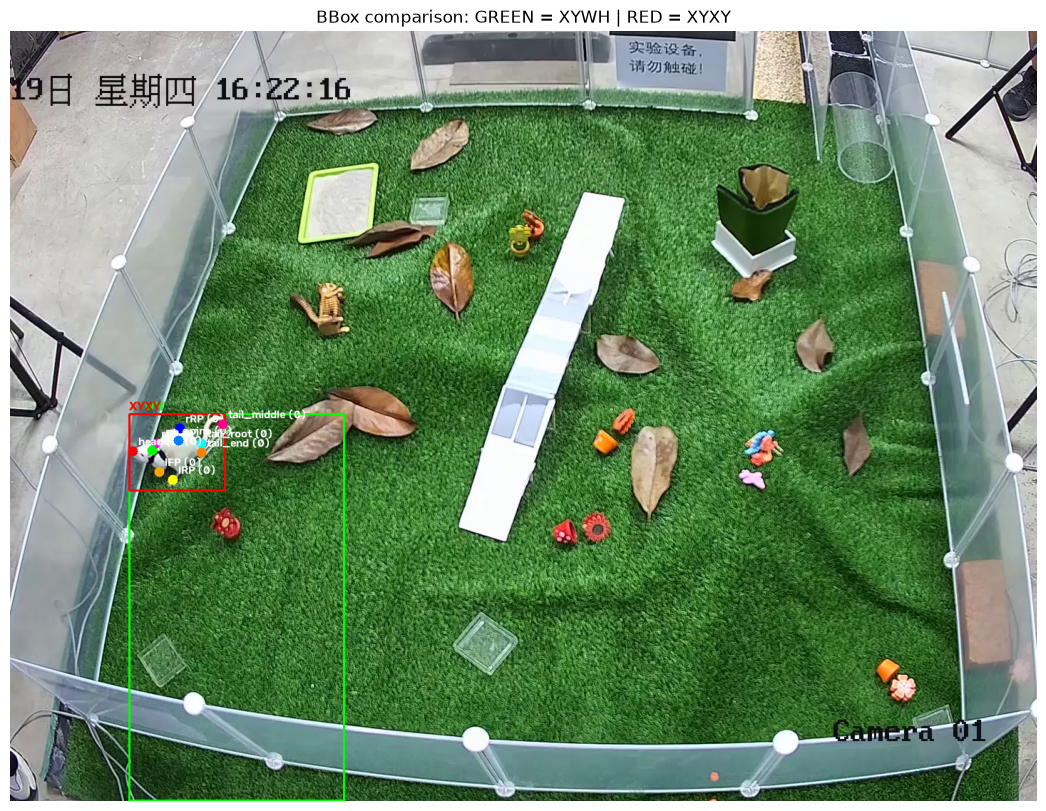

In [10]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt


def first_csv_annotation_validation(csv_path, image_path):

    # Read files
    if not os.path.exists(csv_path) or not os.path.exists(image_path):
        print("Error: File not found")
        return

    df = pd.read_csv(csv_path)

    if df.empty or "BBox" not in df.columns:
        print("Error: Empty CSV or missing BBox column")
        return

    img = cv2.imread(image_path)

    if img is None:
        print("Error: Cannot read image")
        return

    h, w = img.shape[:2]
    row = df.iloc[0]
    vis_img = img.copy()

    print("First annotation:")
    print(row)
    print(f"Image size: {w} x {h}")

    # Read BBox
    try:
        a, b, c, d = map(float, str(row["BBox"]).split("_"))
    except (ValueError, TypeError):
        print("Error: Invalid BBox")
        return

    # Compare XYWH and XYXY
    boxes = {
        "XYWH": (a, b, a + c, b + d),
        "XYXY": (a, b, c, d)
    }

    colors = {
        "XYWH": (0, 255, 0),
        "XYXY": (0, 0, 255)
    }

    for name, (x1, y1, x2, y2) in boxes.items():

        width = x2 - x1
        height = y2 - y1

        print(f"\n{name}:")
        print(f"Coordinates: {x1}, {y1}, {x2}, {y2}")

        if width <= 0 or height <= 0:
            print("Warning: Invalid box size")
            continue

        print("YOLO:",
              (x1 + x2) / (2 * w),
              (y1 + y2) / (2 * h),
              width / w,
              height / h)

        # Draw box
        x1, y1, x2, y2 = map(
            int, (max(0, x1), max(0, y1),
                  min(w - 1, x2), min(h - 1, y2))
        )

        if x2 > x1 and y2 > y1:
            cv2.rectangle(vis_img, (x1, y1), (x2, y2),
                          colors[name], 2)
            cv2.putText(vis_img, name, (x1, max(20, y1 - 5)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                        colors[name], 2)

    # Draw keypoints
    colors_list = [
        (255, 0, 0), (0, 255, 255), (255, 0, 255),
        (0, 165, 255), (255, 255, 0), (0, 0, 255),
        (0, 255, 0), (255, 128, 0), (128, 0, 255),
        (0, 128, 255)
    ]

    for i, col in enumerate(KEYPOINT_COLUMNS):

        if col not in df.columns or pd.isna(row[col]):
            continue

        try:
            x, y, v = map(float, str(row[col]).split("_"))
        except ValueError:
            print(f"Invalid keypoint: {col}")
            continue

        x, y = int(round(x)), int(round(y))

        if not (0 <= x < w and 0 <= y < h):
            print(f"Keypoint outside image: {col}")
            continue

        cv2.circle(vis_img, (x, y), 7, colors_list[i % len(colors_list)], -1)
        cv2.putText(vis_img, f"{col} ({int(v)})", (x + 8, max(15, y - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

    # Show image
    plt.figure(figsize=(14, 10))
    plt.imshow(cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB))
    plt.title("BBox comparison: GREEN = XYWH | RED = XYXY")
    plt.axis("off")
    plt.show()


image_path = os.path.join(
    BASE_FOLDER, "Tilt_Indoor", "20210819_1-1_0.jpg"
)

first_csv_annotation_validation(CSV_FILE, image_path)

# CHECKING V VALUES IN CSV (if formate is x_y_v)

In [4]:
import os
from collections import Counter
import pandas as pd


def check_visibility_values(csv_file):
    try:
        df = pd.read_csv(csv_file, dtype=str)
    except Exception as error:
        print(f"ERROR: Could not read CSV: {error}")
        return

    v_counter = Counter()
    total_keypoints = 0
    invalid_format_count = 0

    # Points with coordinates (x > 0 or y > 0) but v = 0
    non_zero_coords_with_v0 = 0
    # Points with coordinates (0, 0) and v = 0 (missing points)
    zero_coords_with_v0 = 0

    for index, row in df.iterrows():
        for kpt_name in KEYPOINT_COLUMNS:
            kpt = parse_keypoint(row.get(kpt_name))

            if kpt is None:
                invalid_format_count += 1
                continue

            x, y, v = kpt
            v_val = int(v) if v.is_integer() else v

            v_counter[v_val] += 1
            total_keypoints += 1

            if v_val == 0:
                if x == 0 and y == 0:
                    zero_coords_with_v0 += 1
                else:
                    non_zero_coords_with_v0 += 1

    print(f"Total keypoints parsed : {total_keypoints}")
    print(f"Invalid / Missing format: {invalid_format_count}")
    print()
    print("V values distribution:")
    print("-" * 40)

    for v_val, count in sorted(v_counter.items()):
        percentage = (count / total_keypoints) * 100 if total_keypoints > 0 else 0
        print(f"  v = {v_val:<2} : {count:>8} points ({percentage:.2f}%)")

    print("=" * 60)

    # The final result
    unique_v_values = list(v_counter.keys())

    if unique_v_values == [0]:
        print("RESULT: Yes, v is 0 across all anotations in Lawn_scenarios ")
    else:
        print(f"RESULT: No, v is NOT always 0. Found values: {unique_v_values}")

    if non_zero_coords_with_v0 > 0:
        print()
        print(f"[IMPORTANT FINDING]")
        print(f"Found {non_zero_coords_with_v0} keypoints with coordinates (x,y) but v=0")
        print(f"Found {zero_coords_with_v0} keypoints with (0,0) coordinates and v=0.")

# Run
check_visibility_values(CSV_FILE)

Total keypoints parsed : 36700
Invalid / Missing format: 0

V values distribution:
----------------------------------------
  v = 0  :    36700 points (100.00%)
RESULT: Yes, v is 0 across all anotations in Lawn_scenarios 

[IMPORTANT FINDING]
Found 36474 keypoints with coordinates (x,y) but v=0
Found 226 keypoints with (0,0) coordinates and v=0.


# Note:
After the previous check .. and in the image i visualized, there is visible keypoints with v=0 so :

 I assume that (x,y,0) means visible ,
(0,0,0) means not visible and not labeled.

with (x,y,0) keypoints, 0 will be replaced by 2 (because 2 means visible in yolo pose format).

# yolo labels

# turning the annotations in csv file into .txt files and direct it into lables folder

In [ ]:
import os
import cv2
import pandas as pd
from pathlib import Path

# Path configurations relative to notebook location
BASE_DIR = Path("../")

# Dataset directories
images_base_dir = BASE_DIR / "data" / "images"
labels_base_dir = BASE_DIR / "data" / "labels"

def clean_preserve_spaces(path):
    """Normalize slashes and case, but PRESERVE internal/trailing spaces in filename."""
    clean_path = str(path).replace("\\", "/").strip().strip("/")
    # Extract only the base filename without subfolders or extension
    raw_filename = clean_path.split("/")[-1]
    raw_name = os.path.splitext(raw_filename)[0]
    return raw_name


# Read CSV
df = pd.read_csv(CSV_FILE)
df["clean_imageName"] = df["imageName"].apply(clean_preserve_spaces)

# Index disk images for instant O(1) matching
disk_images_map = {}

for root, dirs, files in os.walk(images_base_dir):
    for file in files:
        if os.path.splitext(file)[1].lower() in IMAGE_EXTENSIONS:
            full_path = Path(root) / file
            rel_path = full_path.relative_to(images_base_dir)

            clean_key = clean_preserve_spaces(file)
            disk_images_map[clean_key] = (full_path, rel_path)

print(f"Indexed {len(disk_images_map)} images.")

# Process annotations
created_files = set()
matched_count = 0

for index, row in df.iterrows():
    csv_img_key = row["clean_imageName"]

    # Direct O(1) Lookup
    if csv_img_key not in disk_images_map:
        continue

    matched_full_path, matched_rel_path = disk_images_map[csv_img_key]

    if not matched_full_path.exists():
        continue

    matched_count += 1

    img = cv2.imread(str(matched_full_path))
    if img is None:
        continue
    img_h, img_w, _ = img.shape

    # Construct EXACT .txt path preserving target folder structure (train/val/test)
    full_txt_path = labels_base_dir / matched_rel_path.with_suffix(".txt")
    full_txt_path.parent.mkdir(parents=True, exist_ok=True)

    # Overwrite file if processing it for the first time
    if full_txt_path not in created_files:
        with open(full_txt_path, "w", encoding="utf-8") as f:
            pass
        created_files.add(full_txt_path)

    # BBox parsing "x1_y1_x2_y2"
    bbox_parts = str(row["BBox"]).strip().split("_")
    x1, y1, x2, y2 = [float(val) for val in bbox_parts[:4]]

    # Normalized YOLO BBox [x_center, y_center, width, height]
    bbox_x = ((x1 + x2) / 2.0) / img_w
    bbox_y = ((y1 + y2) / 2.0) / img_h
    bbox_w = (x2 - x1) / img_w
    bbox_h = (y2 - y1) / img_h

    # Parse keypoints "x_y_v" for all 10 keypoints
    keypoints_str = []
    for col in KEYPOINT_COLUMNS:
        if col in row and pd.notna(row[col]):
            kp_parts = str(row[col]).strip().split("_")

            raw_x = float(kp_parts[0])
            raw_y = float(kp_parts[1])
            v_val = int(float(kp_parts[2])) if len(kp_parts) > 2 else 2

            # Visibility logic: 
            if raw_x == 0 and raw_y == 0:
                # If the coordinates are (0, 0), v = 0.
                kp_x = 0.0
                kp_y = 0.0
                kp_v = 0
            else:
                kp_x = raw_x / img_w
                kp_y = raw_y / img_h
                # convert v from 0 to 2 if the point has non-zero x,y coordinates
                kp_v = 2 if v_val == 0 else v_val

            keypoints_str.append(f"{kp_x:.6f} {kp_y:.6f} {kp_v}")
        else:
            keypoints_str.append("0.000000 0.000000 0")


    # Only one class: rat = class 0
    class_id = 0  

    # Line format: <class_id> <bbox> <10_keypoints>
    line = (
        f"{class_id} {bbox_x:.6f} {bbox_y:.6f} {bbox_w:.6f} {bbox_h:.6f} "
        + " ".join(keypoints_str)
    )

    with open(full_txt_path, "a", encoding="utf-8") as f:
        f.write(line + "\n")

print(f"Done! Converted {matched_count} annotations.")

Indexed 3151 images.
Done! Converted 3151 annotations.


# Making sure each image has .txt label file in lables 

In [17]:
import os
from pathlib import Path

# Project root
PROJECT_ROOT = Path.cwd().parent

images_base_dir = PROJECT_ROOT / "data" / "images"
labels_base_dir = PROJECT_ROOT / "data" / "labels"

total_images = 0
matched_labels = 0
missing_labels = []

# Check train, val, and test
for split in ["train", "val", "test"]:

    images_split_dir = images_base_dir / split
    labels_split_dir = labels_base_dir / split

    if not images_split_dir.exists():
        print(f"Warning: {images_split_dir} does not exist.")
        continue

    # Iterate through images
    for file_path in images_split_dir.iterdir():

        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        total_images += 1

        # Expected label:
        # for example: image.jpg -> image.txt
        expected_label_path = (
            labels_split_dir /
            file_path.with_suffix(".txt").name
        )

        if expected_label_path.exists():
            matched_labels += 1

        else:
            missing_labels.append(
                (
                    split,
                    file_path.name,
                    str(expected_label_path)
                )
            )


# Final report

print()
print("=" * 60)
print("DATASET VALIDATION REPORT")
print("=" * 60)

print(f"Total Images Found  : {total_images}")
print(f"Matched Label Files : {matched_labels}")
print(f"Missing Label Files : {len(missing_labels)}")

print("=" * 60)


# Show missing labels

if missing_labels:

    print()
    print("[!] Missing Label Files:")

    for split, image_name, expected_label in missing_labels[:20]:

        print(f"Split : {split}")
        print(f"Image : {image_name}")
        print(f"Label : {expected_label}")
        print()

    if len(missing_labels) > 20:
        print(
            f"... and {len(missing_labels) - 20} more missing labels."
        )

else:

    print()
    print(
        "Perfect! Every image in train, val, and test "
        "has a matching .txt label file."
    )


DATASET VALIDATION REPORT
Total Images Found  : 3151
Matched Label Files : 3151
Missing Label Files : 0

Perfect! Every image in train, val, and test has a matching .txt label file.
